# Single-slide test: one gene vs. the rest

With a single slide there are no conditions to compare, but diffsvg can still say how genes behave along the distance to an anchor. `fit_profiles` fits one curve per gene, and `one_vs_rest` compares the curve of one probe gene with every other gene.

1. The slide, the anchor and the distance to it
2. A quick fit on binned data
3. One gene vs. the rest
4. Comparison with Moran's I and Geary's C: their rankings, the overlap of their top genes, and what each one costs

**Status of this notebook:** the dataset for it is not available yet, so it runs on one legnini slide as a stand-in. Only the cells under "Slide and anchor" have to change for the new data.

In [1]:
# One BLAS thread per process: the fits run in worker processes, and oversubscribed BLAS threads slow them down a lot.
# This has to happen before numpy is imported, so restart the kernel if numpy is already loaded.
import os

for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[var] = "1"

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq
from sklearn.metrics import cohen_kappa_score, confusion_matrix

import diffsvg as dvg

/Users/tim.treis/Documents/GitHub/diffsvg-exact/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Slide and anchor

**To change for the new dataset:** the settings and the anchor column below. The stand-in is the largest SHH slide of legnini, with cells in the top percentile of SHH expression as the anchor, and GLI1 (a direct target of SHH signalling) as the probe.

`MIN_CELLS`: genes must be detected in this many cells. A gene that is absent from the slide has no curve to compare, and its undefined p-value in Moran's I and Geary's C would otherwise blank out their FDR columns for all genes.

In [2]:
DATA_PATH = os.environ.get("DIFFSVG_DATA", "data/legnini23.h5ad")  # TODO: the new dataset
SLIDE_KEY, SLIDE = "sample", "slide1_D2-2"  # TODO: set SLIDE_KEY = None if the file holds one slide
PROBE = "GLI1"  # TODO: the gene to compare against the rest
ANCHOR = "SHH+"  # TODO: an obs column marking the anchor cells
ANCHOR_GROUP = "True"
LAYER = "log1p_norm"
MIN_CELLS = 10
N_WORKERS = int(os.environ.get("DIFFSVG_WORKERS", 4))
ALPHA = 0.05
TOP_N = 20
RESULTS_PATH = os.environ.get("DIFFSVG_RESULTS", "single_slide_test_results.pkl")

timings = {}

In [3]:
adata = sc.read_h5ad(DATA_PATH)
if SLIDE_KEY is not None:
    adata = adata[adata.obs[SLIDE_KEY] == SLIDE].copy()

# TODO: remove for the new dataset if it comes with an anchor column. Stand-in anchor: the top percentile of SHH on this slide.
shh = adata[:, "SHH"].X
shh = (shh.toarray() if hasattr(shh, "toarray") else np.asarray(shh)).ravel()
adata.obs[ANCHOR] = (shh > np.percentile(shh, 99)).astype(str)

expression = adata.layers[LAYER]
detected = np.asarray((expression > 0).sum(axis=0)).ravel()
GENES = list(adata.var_names[detected >= MIN_CELLS])
print(f"{adata.n_obs} cells, {len(GENES)} of {adata.n_vars} genes detected in at least {MIN_CELLS} cells")

sq.tl.var_by_distance(adata, cluster_key=ANCHOR, groups=ANCHOR_GROUP)
adata.obsm["design_matrix"].head()

4318 cells, 82 of 88 genes detected in at least 10 cells


,SHH+,True,True_raw
21936,False,0.346873,953.033699
21937,False,0.158701,436.030824
21938,False,0.178600,490.704206
21939,False,0.209446,575.454186
21940,False,0.114341,314.153250


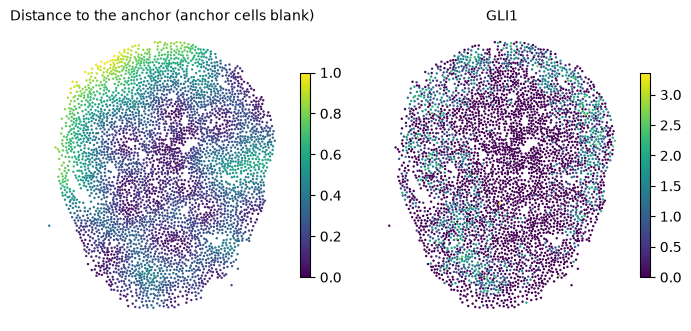

In [4]:
def gene_values(gene):
    values = adata[:, gene].layers[LAYER]
    return (values.toarray() if hasattr(values, "toarray") else np.asarray(values)).ravel()


def tissue_maps(panels, ncols=4):
    """One map per entry of `panels`, {title: values}, on the tissue's own coordinates."""
    ncols = min(ncols, len(panels))
    nrows = (len(panels) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.4 * ncols, 3.2 * nrows), squeeze=False, constrained_layout=True)
    for ax in axes.ravel()[len(panels) :]:
        ax.set_visible(False)
    xy = adata.obsm["spatial"]
    for ax, (title, values) in zip(axes.ravel(), panels.items(), strict=False):
        order = np.argsort(np.nan_to_num(values))  # high values on top
        points = ax.scatter(*xy[order].T, c=values[order], cmap="viridis", s=3, linewidth=0)
        ax.set_title(title, fontsize=10)
        ax.set_aspect("equal")
        ax.set_axis_off()
        fig.colorbar(points, ax=ax, shrink=0.7)


distance = adata.obsm["design_matrix"][ANCHOR_GROUP].to_numpy()
tissue_maps({"Distance to the anchor (anchor cells blank)": distance, PROBE: gene_values(PROBE)})

## 2. A quick fit on binned data

`bin_obs(condition=None)` averages each gene in windows along the distance, and `fit_profiles` fits one curve per gene (exact posterior). No condition term and no interaction, so there is no condition test here: the differences come from comparing genes in the next step.

In [5]:
t0 = time.perf_counter()
dvg.pp.bin_obs(adata, anchor=ANCHOR_GROUP, condition=None, genes=GENES, layer=LAYER, n_bins=50)
dvg.tl.fit_profiles(adata, dvg.tl.setup_model(adata), n_workers=N_WORKERS)
timings["diffsvg: bins + fit_profiles"] = time.perf_counter() - t0

profiles = adata.varm["dsvg_profiles_mean"].loc[GENES]
diagnostics = adata.varm["dsvg_profiles_diagnostics"].loc[GENES]
print(
    f"{timings['diffsvg: bins + fit_profiles']:.1f} s, largest posterior mass at the grid edge {diagnostics['exact_edge_mass'].max():.1e}"
)

Fitting DiffSVG profiles:   0%|          | 0/82 [00:00<?, ?it/s]

Fitting DiffSVG profiles: 100%|██████████| 82/82 [00:00<00:00, 369423.12it/s]

0.2 s, largest posterior mass at the grid edge 6.0e-22


## 3. One gene vs. the rest

`fit_profiles` keeps each gene's posterior covariance, so `one_vs_rest` tests every pair with the parallel-curves test: does the other gene's curve differ from the probe's in shape, by more than `tau`, rather than only in level? `delta` is the signed area between the curves (negative when the probe sits below), and `T` their mean squared gap. The test removes the level, so a gene with the probe's shape at another expression level is not called different.

In [6]:
t0 = time.perf_counter()
ovr = dvg.tl.one_vs_rest(adata, PROBE)
timings["diffsvg: one_vs_rest"] = time.perf_counter() - t0

print(
    f"{(ovr['parallel_pval_adj'] < ALPHA).sum()} of {len(ovr)} genes differ in shape from {PROBE} (BH-adjusted p < {ALPHA})"
)
ovr.sort_values("parallel_stat", ascending=False).head(15)

80 of 81 genes differ in shape from GLI1 (BH-adjusted p < 0.05)


,delta,T,shape_diff,parallel_stat,parallel_pval,parallel_pval_adj
FOS,0.239678,0.340217,1.824277,908.270598,3.357907e-162,2.719905e-160
JUNB,-0.159309,0.344907,1.886709,886.542523,4.978402e-160,1.344169e-158
AC129492.1,-0.657275,0.819488,2.093760,883.378840,9.526847e-162,3.858373e-160
JUN,-0.605278,0.789950,2.140606,857.259606,5.397493e-157,1.092992e-155
Circ.RMST,-1.753059,3.467892,1.925930,719.351171,7.917589e-126,1.282649e-124
NR4A3,0.308314,0.208876,1.174913,526.937234,9.518603e-84,1.285011e-82
Circ.CDR1,-1.657118,3.064235,1.604581,489.792943,8.896824e-82,1.029490e-80
FOSL2,0.443328,0.291561,1.084832,486.736340,3.000035e-72,3.037535e-71
FOSB,0.469310,0.299262,1.007238,461.344096,1.252987e-67,1.014920e-66
SHH,0.385490,0.244414,1.082669,458.664760,3.312471e-68,2.981224e-67


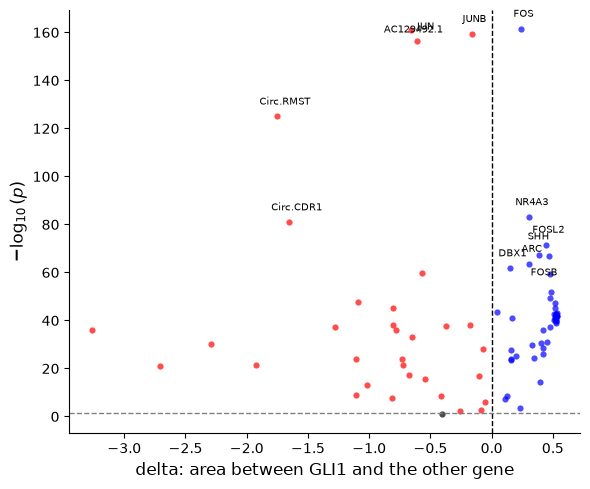

In [7]:
dvg.pl.plot_volcano(ovr, x="delta", pvalue="parallel_pval", pvalue_adj="parallel_pval_adj", n_label=12, figsize=(6, 5))
plt.gca().set_xlabel(f"delta: area between {PROBE} and the other gene");

The probe's curve next to the genes closest to it and farthest from it. The left panel keeps the levels, as `T` does. The right panel removes each gene's mean, which shows the genes whose *shape* matches best.

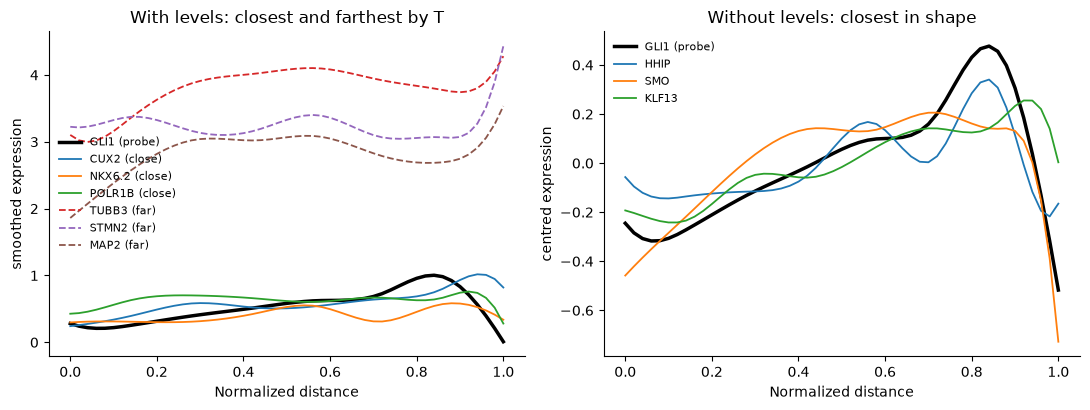

In [8]:
x = profiles.columns.to_numpy(dtype=float)
closest, farthest = list(ovr["T"].nsmallest(3).index), list(ovr["T"].nlargest(3).index)
centred = profiles.sub(profiles.mean(axis=1), axis=0)
gap_shape = ((centred.drop(index=PROBE) - centred.loc[PROBE]) ** 2).mean(axis=1)
same_shape = list(gap_shape.nsmallest(3).index)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(x, profiles.loc[PROBE], color="black", lw=2.5, label=f"{PROBE} (probe)")
for gene in closest:
    axes[0].plot(x, profiles.loc[gene], lw=1.3, ls="-", label=f"{gene} (close)")
for gene in farthest:
    axes[0].plot(x, profiles.loc[gene], lw=1.3, ls="--", label=f"{gene} (far)")
axes[0].set(xlabel="Normalized distance", ylabel="smoothed expression", title="With levels: closest and farthest by T")
axes[1].plot(x, centred.loc[PROBE], color="black", lw=2.5, label=f"{PROBE} (probe)")
for gene in same_shape:
    axes[1].plot(x, centred.loc[gene], lw=1.3, label=gene)
axes[1].set(xlabel="Normalized distance", ylabel="centred expression", title="Without levels: closest in shape")
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout();

## 4. Comparison with Moran's I and Geary's C

Moran's I and Geary's C ask whether neighbouring cells have similar expression, whatever the pattern. They need a spatial graph and no anchor.

### What counts as a diffsvg call

The comparison needs one yes or no per gene, which a comparison against a patterned probe does not give: a flat gene differs from a patterned probe too, and would be flagged. So here the probe is the **flattest gene** and levels are removed: `one_vs_rest` on centred curves, against the gene with the smallest centred curve. A gene is then called if its curve has an unusually strong shape along the distance. This is the same function as above, reading a table of centred curves through `profiles_key`.

The two kinds of test are not asking the same question: a gene that forms patches unrelated to the anchor is spatially variable for Moran's I and flat along the distance for diffsvg. So what matters here is how far their rankings and top genes agree. This is not accuracy, since there is no ground truth, and either side of a disagreement may be right.

### Fitting them

All three use the same genes and the same layer. The first call of each statistic compiles its code, so a warm-up on two genes keeps that out of the timings. `n_perms=None` uses the analytic p-value, the fastest setting; a permutation run is timed as well, as the usual alternative.

In [9]:
t0 = time.perf_counter()
sq.gr.spatial_neighbors(adata, coord_type="generic", delaunay=True)
timings["squidpy: spatial graph"] = time.perf_counter() - t0

for mode in ("moran", "geary"):
    sq.gr.spatial_autocorr(adata, mode=mode, genes=GENES[:2], layer=LAYER, n_perms=None, n_jobs=1)

t0 = time.perf_counter()
sq.gr.spatial_autocorr(
    adata, mode="moran", genes=GENES, layer=LAYER, n_perms=100, n_jobs=N_WORKERS, show_progress_bar=False
)
timings["squidpy: Moran's I, 100 permutations"] = time.perf_counter() - t0

t0 = time.perf_counter()
sq.gr.spatial_autocorr(adata, mode="moran", genes=GENES, layer=LAYER, n_perms=None, n_jobs=1)
timings["squidpy: Moran's I, analytic"] = time.perf_counter() - t0

t0 = time.perf_counter()
sq.gr.spatial_autocorr(adata, mode="geary", genes=GENES, layer=LAYER, n_perms=None, n_jobs=1)
timings["squidpy: Geary's C, analytic"] = time.perf_counter() - t0

moran, geary = adata.uns["moranI"].loc[GENES], adata.uns["gearyC"].loc[GENES]

# diffsvg: the rest against the flattest gene, on centred curves
adata.varm["dsvg_centred_mean"] = centred.reindex(adata.var_names)
flat_probe = (centred**2).mean(axis=1).idxmin()
t0 = time.perf_counter()
shape_call = dvg.tl.one_vs_rest(adata, flat_probe, profiles_key="dsvg_centred")
timings["diffsvg: one_vs_rest, flat probe"] = time.perf_counter() - t0
print(f"Flattest gene, used as the reference: {flat_probe}")

# Keeps every gene: the flat probe itself is, by definition, not called.
table = pd.DataFrame(
    {
        "diffsvg T": shape_call["T"].reindex(GENES).fillna(0.0),
        "diffsvg p": shape_call["gamma_pval"].reindex(GENES).fillna(1.0),
        "Moran I": moran["I"],
        "Moran p": moran["pval_norm"],
        "Geary C": geary["C"],
        "Geary p": geary["pval_norm"],
    }
)
pd.to_pickle({"table": table, "ovr": ovr, "timings": timings}, RESULTS_PATH)
table.sort_values("diffsvg T", ascending=False).head(10).round(4)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/var/folders/qg/qgc908995g3fc8qtss2fsbhhxyxxj4/T/ipykernel_76626/3738058807.py:2: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata, coord_type="generic", delaunay=True)


Flattest gene, used as the reference: LUM


,diffsvg T,diffsvg p,Moran I,Moran p,Geary C,Geary p
NKX6.1,0.4638,0.0714,0.7480,0.0,0.2498,0.0
IRX3,0.2417,0.1654,0.5480,0.0,0.4477,0.0
MNX1,0.1984,0.1989,0.5360,0.0,0.4622,0.0
PROM1,0.1980,0.1993,0.5244,0.0,0.4723,0.0
ISL1,0.1921,0.2045,0.4333,0.0,0.5652,0.0
JUN,0.1821,0.2139,0.4361,0.0,0.5556,0.0
PTCH1,0.1753,0.2206,0.5584,0.0,0.4360,0.0
PAX6,0.1744,0.2216,0.5189,0.0,0.4759,0.0
AC129492.1,0.1724,0.2236,0.5710,0.0,0.4234,0.0
GLI3,0.1681,0.2281,0.5088,0.0,0.4873,0.0


### Rankings

How strong each gene is under each test, over all genes. Geary's C is inverted, so that for all three a larger value means more spatial structure.

,diffsvg T,Moran I,1 - Geary C
diffsvg T,1.00,0.87,0.87
Moran I,0.87,1.00,0.99
1 - Geary C,0.87,0.99,1.00


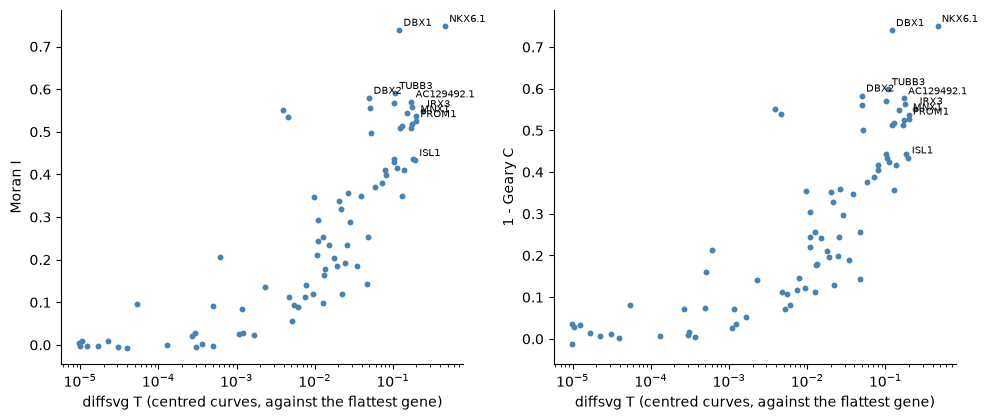

In [10]:
strength = pd.DataFrame(
    {"diffsvg T": table["diffsvg T"], "Moran I": table["Moran I"], "1 - Geary C": 1 - table["Geary C"]}
)
display(strength.corr(method="spearman").round(2))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
for ax, column in zip(axes, ["Moran I", "1 - Geary C"], strict=True):
    ax.scatter(strength["diffsvg T"], strength[column], s=18, color="steelblue", linewidth=0)
    ax.set_xscale("log")
    ax.set(xlabel="diffsvg T (centred curves, against the flattest gene)", ylabel=column)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for gene in strength[column].nlargest(5).index.union(strength["diffsvg T"].nlargest(5).index):
        ax.annotate(
            gene,
            (strength.loc[gene, "diffsvg T"], strength.loc[gene, column]),
            xytext=(3, 3),
            textcoords="offset points",
            fontsize=7,
        )
fig.tight_layout();

### Overlap of the top genes

Each test calls its `TOP_N` strongest genes, so all of them call the same number and only the rankings are compared. The confusion matrices count the genes by the two calls, and the table repeats the overlap for other list sizes.

,diffsvg / Moran's I,diffsvg / Geary's C,Moran's I / Geary's C
top 5,1,1,5
top 10,4,4,10
top 20,14,14,19
top 40,34,34,40


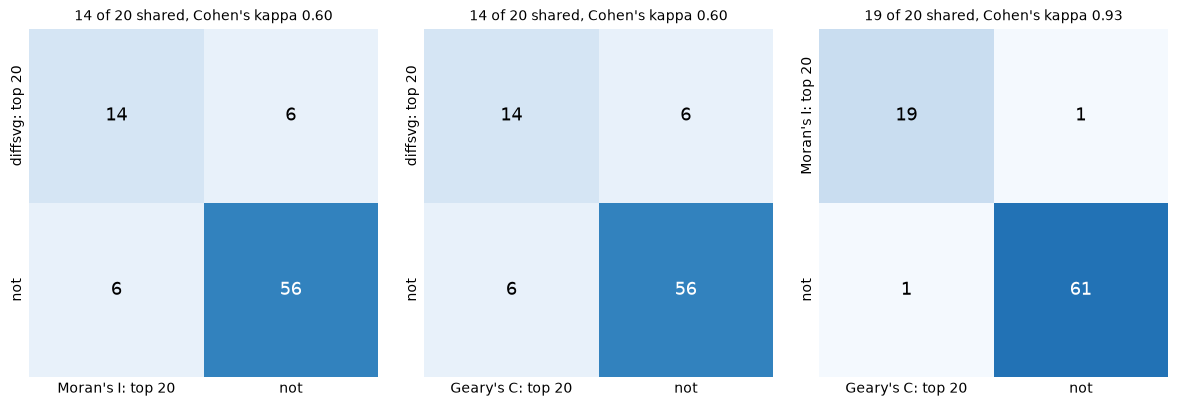

In [11]:
top_ranks = {
    "diffsvg": table["diffsvg T"].rank(ascending=False),
    "Moran's I": table["Moran I"].rank(ascending=False),
    "Geary's C": table["Geary C"].rank(ascending=True),
}
calls_top = {name: ranks <= TOP_N for name, ranks in top_ranks.items()}
PAIRS = [("diffsvg", "Moran's I"), ("diffsvg", "Geary's C"), ("Moran's I", "Geary's C")]


def draw_confusion(ax, calls, a, b):
    """Counts of genes by the call of `a` (rows) and `b` (columns); every cell carries its count."""
    matrix = confusion_matrix(calls[a], calls[b], labels=[True, False])
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=len(table))
    ax.set_xticks([0, 1], [f"{b}: top {TOP_N}", "not"])
    ax.set_yticks([0, 1], [f"{a}: top {TOP_N}", "not"], rotation=90, va="center")
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    for i, j in np.ndindex(matrix.shape):
        ax.text(
            j,
            i,
            matrix[i, j],
            ha="center",
            va="center",
            fontsize=13,
            color="white" if matrix[i, j] > len(table) / 2 else "black",
        )
    ax.set_title(
        f"{matrix[0, 0]} of {TOP_N} shared, Cohen's kappa {cohen_kappa_score(calls[a], calls[b]):.2f}", fontsize=10
    )


fig, axes = plt.subplots(1, 3, figsize=(12, 3.9))
for ax, (a, b) in zip(axes, PAIRS, strict=True):
    draw_confusion(ax, calls_top, a, b)
fig.tight_layout()

sizes = [n for n in (5, 10, 20, 40) if n < len(table)]
pd.DataFrame(
    {
        f"{a} / {b}": {f"top {n}": int(((top_ranks[a] <= n) & (top_ranks[b] <= n)).sum()) for n in sizes}
        for a, b in PAIRS
    }
)

### Number of significant genes

For reference only, because the counts are far apart by construction. The p-values of Moran's I and Geary's C shrink with the number of cells, while the Gamma null of diffsvg treats the lower 90% of its panel as null, so it can only call a small part of a panel. Unadjusted `p < ALPHA`; Moran's I and Geary's C only in the direction of positive autocorrelation (`I > 0`, `C < 1`).

In [12]:
pd.Series(
    {
        "diffsvg": (table["diffsvg p"] < ALPHA).sum(),
        "Moran's I": ((table["Moran p"] < ALPHA) & (table["Moran I"] > 0)).sum(),
        "Geary's C": ((table["Geary p"] < ALPHA) & (table["Geary C"] < 1)).sum(),
    },
    name=f"genes of {len(table)}",
).to_frame()

,genes of 82
diffsvg,0
Moran's I,69
Geary's C,73


### Where they disagree

The genes in the top list of one test only, and maps of the strongest of each. A Moran-only gene with a pattern unrelated to the distance is the expected kind of disagreement: spatial structure the anchor does not explain.

Top by Moran's I only: DBX2, MAP2, STMN2, OTX2, PAX7, OTP
Top by diffsvg only: ISL1, JUN, JUNB, NEUROG2, Circ.RMST, GLI2


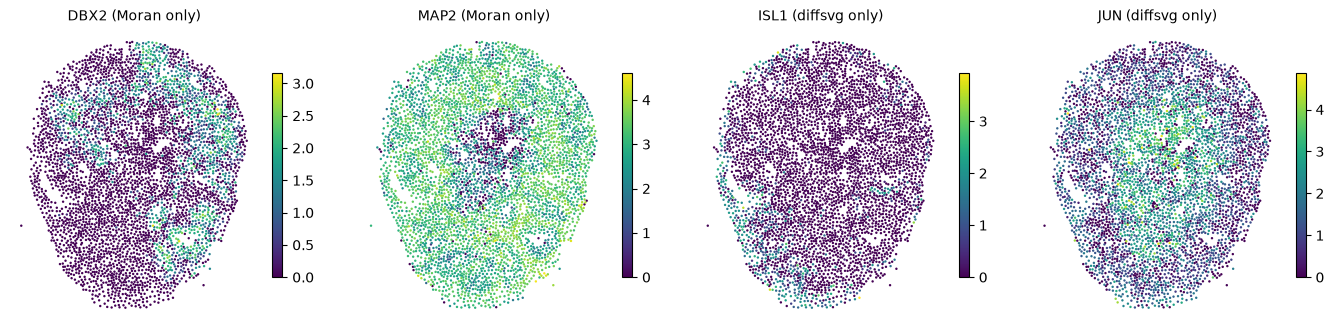

In [13]:
moran_only = table.loc[calls_top["Moran's I"] & ~calls_top["diffsvg"]].sort_values("Moran I", ascending=False)
diffsvg_only = table.loc[calls_top["diffsvg"] & ~calls_top["Moran's I"]].sort_values("diffsvg T", ascending=False)
print("Top by Moran's I only:", ", ".join(moran_only.index))
print("Top by diffsvg only:", ", ".join(diffsvg_only.index))

panels = {f"{gene} (Moran only)": gene_values(gene) for gene in moran_only.index[:2]}
panels |= {f"{gene} (diffsvg only)": gene_values(gene) for gene in diffsvg_only.index[:2]}
if panels:
    tissue_maps(panels)

### What each one costs

Wall-clock time on this slide. The diffsvg fit used `N_WORKERS` processes, the analytic statistics one. Moran's I and Geary's C need one sparse matrix product per gene, whereas diffsvg samples a model per gene, so the gap is expected. Its size depends on the slide: the cost of a binned fit depends on the number of bins, not of cells, while the cost of the two statistics grows with the size of the graph. What the extra time buys is a curve per gene with an uncertainty band, in the units of the expression, tied to one anchor.

In [14]:
cost = pd.Series(timings, name="seconds").to_frame()
cost["per gene (ms)"] = 1000 * cost["seconds"] / len(GENES)
total_moran = timings["squidpy: spatial graph"] + timings["squidpy: Moran's I, analytic"]
total_diffsvg = timings["diffsvg: bins + fit_profiles"] + timings["diffsvg: one_vs_rest, flat probe"]
print(
    f"From the slide to a call per gene: diffsvg {total_diffsvg:.1f} s, Moran's I {total_moran:.2f} s, {total_diffsvg / total_moran:.0f} times as long"
)
cost.round(2)

From the slide to a call per gene: diffsvg 0.2 s, Moran's I 0.14 s, 2 times as long


,seconds,per gene (ms)
diffsvg: bins + fit_profiles,0.21,2.56
diffsvg: one_vs_rest,0.03,0.35
squidpy: spatial graph,0.02,0.30
"squidpy: Moran's I, 100 permutations",31.13,379.66
"squidpy: Moran's I, analytic",0.12,1.46
"squidpy: Geary's C, analytic",0.09,1.10
"diffsvg: one_vs_rest, flat probe",0.02,0.25
